In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import urllib.request

quickdraw_dir = Path("../data/quickdraw")
quickdraw_dir.mkdir(parents=True, exist_ok=True)

print("Quick Draw folder:", quickdraw_dir)

Quick Draw folder: ../data/quickdraw


In [2]:
categories = ["airplane", "apple", "cat"]

base_url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"

for category in categories:
    url = f"{base_url}{category}.npy"
    destination = quickdraw_dir / f"{category}.npy"

    if destination.exists():
        print(f"{category}: already downloaded")
    else:
        print(f"Downloading {category}...")
        urllib.request.urlretrieve(url, destination)
        print(f"{category}: finished")

print("\nDone.")

airplane: already downloaded
apple: already downloaded
cat: already downloaded

Done.


In [3]:
for category in categories:
    path = quickdraw_dir / f"{category}.npy"
    data = np.load(path)

    print(
        f"{category:10s} | "
        f"shape = {data.shape} | "
        f"dtype = {data.dtype} | "
        f"file size = {path.stat().st_size / 1024**2:.1f} MB"
    )

airplane   | shape = (151623, 784) | dtype = uint8 | file size = 113.4 MB
apple      | shape = (144722, 784) | dtype = uint8 | file size = 108.2 MB
cat        | shape = (123202, 784) | dtype = uint8 | file size = 92.1 MB


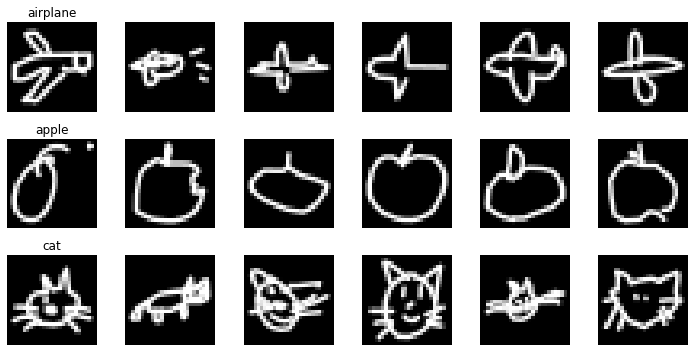

In [4]:
fig, axes = plt.subplots(3, 6, figsize=(10, 5))

for row, category in enumerate(categories):
    data = np.load(quickdraw_dir / f"{category}.npy")

    # Show the first 6 examples
    for col in range(6):
        image = data[col].reshape(28, 28)

        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(category)

plt.tight_layout()
plt.show()

In [5]:
for category in categories:
    data = np.load(quickdraw_dir / f"{category}.npy")

    print(
        f"{category:10s} | "
        f"min = {data.min()} | "
        f"max = {data.max()} | "
        f"mean = {data.mean():.2f}"
    )

airplane   | min = 0 | max = 255 | mean = 40.53
apple      | min = 0 | max = 255 | mean = 37.69
cat        | min = 0 | max = 255 | mean = 50.66


In [6]:
categories = [
    "airplane",
    "apple",
    "bicycle",
    "cat",
    "fish",
    "guitar",
    "house",
    "tree"
]

base_url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"

for category in categories:
    destination = quickdraw_dir / f"{category}.npy"

    if destination.exists():
        print(f"{category}: already downloaded")
    else:
        url = f"{base_url}{category}.npy"
        print(f"Downloading {category}...")
        urllib.request.urlretrieve(url, destination)
        print(f"{category}: finished")

print("\nAll selected categories are available.")

airplane: already downloaded
apple: already downloaded
bicycle: already downloaded
cat: already downloaded
fish: already downloaded
guitar: already downloaded
house: already downloaded
tree: already downloaded

All selected categories are available.


In [7]:
for category in categories:
    path = quickdraw_dir / f"{category}.npy"
    data = np.load(path)

    print(
        f"{category:10s} | "
        f"drawings = {len(data):,} | "
        f"features = {data.shape[1]} | "
        f"size = {path.stat().st_size / 1024**2:.1f} MB"
    )

airplane   | drawings = 151,623 | features = 784 | size = 113.4 MB
apple      | drawings = 144,722 | features = 784 | size = 108.2 MB
bicycle    | drawings = 126,527 | features = 784 | size = 94.6 MB
cat        | drawings = 123,202 | features = 784 | size = 92.1 MB
fish       | drawings = 134,150 | features = 784 | size = 100.3 MB
guitar     | drawings = 120,451 | features = 784 | size = 90.1 MB
house      | drawings = 135,420 | features = 784 | size = 101.3 MB
tree       | drawings = 144,721 | features = 784 | size = 108.2 MB


In [8]:
samples_per_class = 3000
rng = np.random.default_rng(42)

X_parts = []
y_parts = []

class_to_id = {category: i for i, category in enumerate(categories)}

for category in categories:
    data = np.load(quickdraw_dir / f"{category}.npy")

    # Randomly choose 3,000 different drawings
    indices = rng.choice(
        len(data),
        size=samples_per_class,
        replace=False
    )

    sampled = data[indices]

    X_parts.append(sampled)
    y_parts.append(
        np.full(samples_per_class, class_to_id[category])
    )

X = np.concatenate(X_parts)
y = np.concatenate(y_parts)

# Shuffle all classes together
shuffle_indices = rng.permutation(len(X))
X = X[shuffle_indices]
y = y[shuffle_indices]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X dtype:", X.dtype)
print("Classes:", class_to_id)

X shape: (24000, 784)
y shape: (24000,)
X dtype: uint8
Classes: {'airplane': 0, 'apple': 1, 'bicycle': 2, 'cat': 3, 'fish': 4, 'guitar': 5, 'house': 6, 'tree': 7}


In [9]:
unique, counts = np.unique(y, return_counts=True)

id_to_class = {v: k for k, v in class_to_id.items()}

print("Class distribution:")

for class_id, count in zip(unique, counts):
    print(f"{id_to_class[class_id]:10s}: {count}")

Class distribution:
airplane  : 3000
apple     : 3000
bicycle   : 3000
cat       : 3000
fish      : 3000
guitar    : 3000
house     : 3000
tree      : 3000


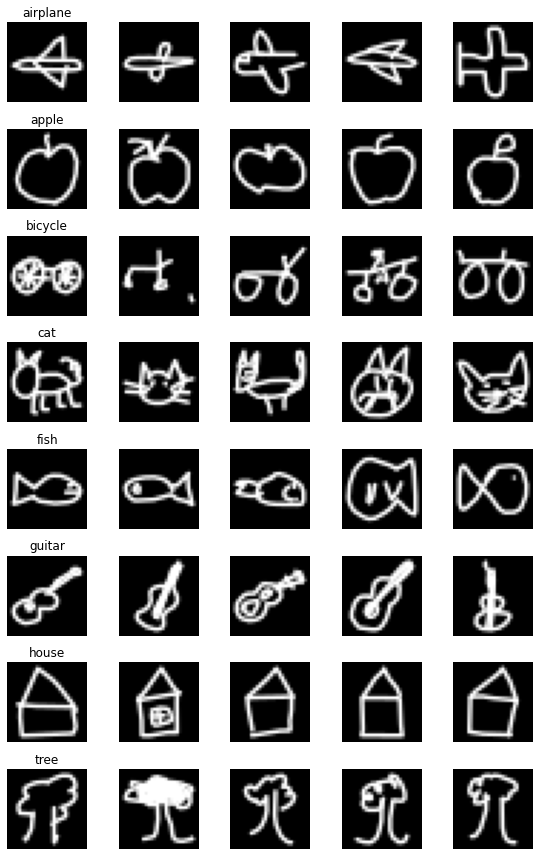

In [10]:
fig, axes = plt.subplots(
    len(categories),
    5,
    figsize=(8, 12)
)

for row, category in enumerate(categories):
    class_id = class_to_id[category]

    # Find 5 samples from this class
    sample_indices = np.where(y == class_id)[0][:5]

    for col, idx in enumerate(sample_indices):
        image = X[idx].reshape(28, 28)

        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(category)

plt.tight_layout()
plt.savefig("../figures/quickdraw_sample_grid.png", dpi=150, bbox_inches="tight")
plt.show()

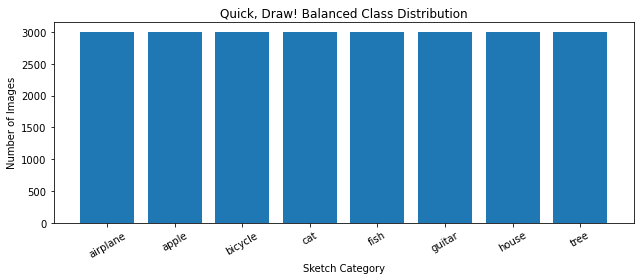

In [11]:
class_counts = {
    id_to_class[class_id]: count
    for class_id, count in zip(unique, counts)
}

plt.figure(figsize=(9, 4))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Quick, Draw! Balanced Class Distribution")
plt.xlabel("Sketch Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig("../figures/quickdraw_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
X_images = X.reshape(-1, 28, 28, 1).astype("float32") / 255.0

print("CNN input shape:", X_images.shape)
print("Data type:", X_images.dtype)
print("Minimum pixel value:", X_images.min())
print("Maximum pixel value:", X_images.max())

CNN input shape: (24000, 28, 28, 1)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [13]:
from sklearn.model_selection import train_test_split

# First: 80% train, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X_images,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second: split temporary set equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (19200, 28, 28, 1) (19200,)
Validation: (2400, 28, 28, 1) (2400,)
Test: (2400, 28, 28, 1) (2400,)


In [14]:
def show_distribution(name, labels):
    unique_ids, counts = np.unique(labels, return_counts=True)

    print(f"\n{name}:")
    for class_id, count in zip(unique_ids, counts):
        print(f"{id_to_class[class_id]:10s}: {count}")

show_distribution("TRAIN", y_train)
show_distribution("VALIDATION", y_val)
show_distribution("TEST", y_test)


TRAIN:
airplane  : 2400
apple     : 2400
bicycle   : 2400
cat       : 2400
fish      : 2400
guitar    : 2400
house     : 2400
tree      : 2400

VALIDATION:
airplane  : 300
apple     : 300
bicycle   : 300
cat       : 300
fish      : 300
guitar    : 300
house     : 300
tree      : 300

TEST:
airplane  : 300
apple     : 300
bicycle   : 300
cat       : 300
fish      : 300
guitar    : 300
house     : 300
tree      : 300


In [15]:
output_path = quickdraw_dir / "quickdraw_8class_processed.npz"

np.savez_compressed(
    output_path,
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
    categories=np.array(categories)
)

print("Saved to:", output_path)
print(f"File size: {output_path.stat().st_size / 1024**2:.1f} MB")

Saved to: ../data/quickdraw/quickdraw_8class_processed.npz
File size: 9.6 MB
